# 06. Калибровка вероятностей и порог с учётом стоимости

**Цель:** проверить, можно ли доверять вероятностям Random Forest, сравнить методы калибровки и посмотреть, как меняется оптимальный порог при разных предположениях о стоимости ошибок.

Ноутбук использует уже обученную модель из `models/churn_model.joblib` и подготовленные данные из `data/processed/`.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv", usecols=["Churn"]).squeeze("columns")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv", usecols=["Churn"]).squeeze("columns")

best_model = joblib.load(MODELS_DIR / "churn_model.joblib")

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Модель:", type(best_model.named_steps["model"]).__name__)

Train: (5634, 19)
Test: (1409, 19)
Модель: RandomForestClassifier


## 1. Калибровка вероятностей

Random Forest оценивает вероятность как среднюю долю голосов деревьев. Такие вероятности не обязаны быть калиброванными: значение 0,30 не всегда означает, что среди похожих клиентов действительно уходит 30%.

Проверю это с помощью Brier score, log loss и калибровочной кривой. Чем ниже Brier score и log loss, тем лучше вероятности согласуются с фактическими исходами.

In [3]:
def probability_metrics(y_true, probabilities):
    return {
        "brier": brier_score_loss(y_true, probabilities),
        "log_loss": log_loss(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
    }


test_probabilities = best_model.predict_proba(X_test)[:, 1]
uncalibrated_metrics = probability_metrics(y_test, test_probabilities)

pd.DataFrame([uncalibrated_metrics], index=["Без калибровки"]).round(4)

,brier,log_loss,roc_auc,pr_auc
Без калибровки,0.1364,0.419,0.8425,0.6548


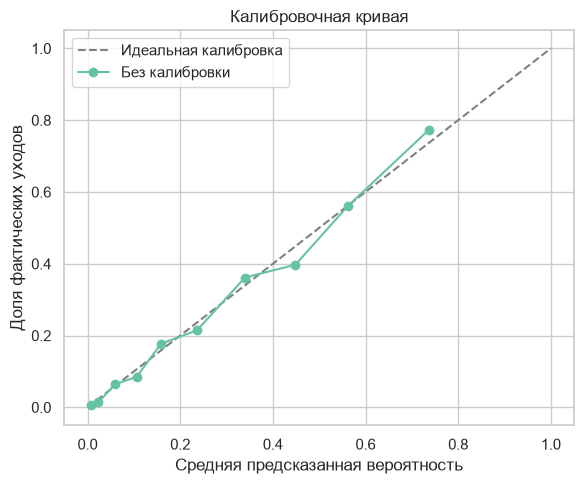

In [4]:
def plot_calibration_curve(ax, y_true, probabilities, label, n_bins=10):
    fraction_of_positives, mean_predicted_value = calibration_curve(
        y_true,
        probabilities,
        n_bins=n_bins,
        strategy="quantile",
    )
    ax.plot(
        mean_predicted_value,
        fraction_of_positives,
        marker="o",
        label=label,
    )


fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Идеальная калибровка")
plot_calibration_curve(ax, y_test, test_probabilities, "Без калибровки")

ax.set_xlabel("Средняя предсказанная вероятность")
ax.set_ylabel("Доля фактических уходов")
ax.set_title("Калибровочная кривая")
ax.legend()

plt.tight_layout()
plt.show()

Сравню два метода калибровки:

- **sigmoid** — подбирает параметры логистической функции, устойчив на небольших выборках;
- **isotonic** — строит монотонную ступенчатую функцию, гибче, но сильнее склонен к переобучению.

Оба калибратора обучаются на train с внутренней 5-fold кросс-валидацией, тест используется только для итоговой оценки.

In [5]:
calibrated_models = {
    "Sigmoid": CalibratedClassifierCV(best_model, method="sigmoid", cv=5),
    "Isotonic": CalibratedClassifierCV(best_model, method="isotonic", cv=5),
}

calibrated_probabilities = {}
calibration_rows = [{"Метод": "Без калибровки", **uncalibrated_metrics}]

for name, model in calibrated_models.items():
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_test)[:, 1]
    calibrated_probabilities[name] = probabilities
    calibration_rows.append({"Метод": name, **probability_metrics(y_test, probabilities)})

calibration_comparison = pd.DataFrame(calibration_rows).set_index("Метод")
calibration_comparison.round(4)

,brier,log_loss,roc_auc,pr_auc
Метод,,,,
Без калибровки,0.1364,0.4190,0.8425,0.6548
Sigmoid,0.1367,0.4240,0.8441,0.6558
Isotonic,0.1361,0.4186,0.8443,0.6568


In [6]:
calibration_comparison.round(4).to_csv(
    REPORTS_DIR / "calibration_metrics.csv",
    encoding="utf-8",
)

print("Сохранено:", REPORTS_DIR / "calibration_metrics.csv")

Сохранено: C:\Users\rrr9g\OneDrive\Рабочий стол\Projects\project1\reports\calibration_metrics.csv


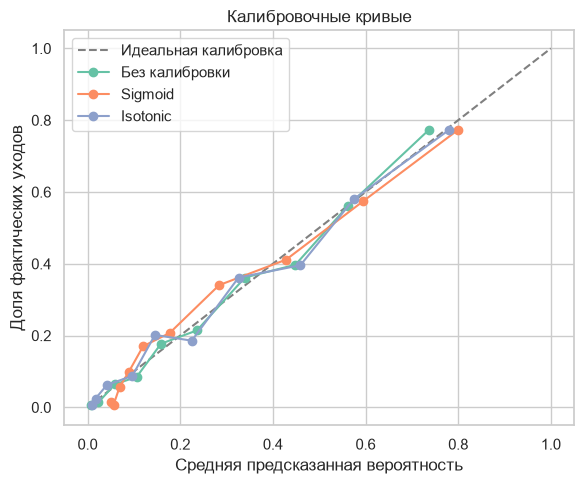

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Идеальная калибровка")
plot_calibration_curve(ax, y_test, test_probabilities, "Без калибровки")

for name, probabilities in calibrated_probabilities.items():
    plot_calibration_curve(ax, y_test, probabilities, name)

ax.set_xlabel("Средняя предсказанная вероятность")
ax.set_ylabel("Доля фактических уходов")
ax.set_title("Калибровочные кривые")
ax.legend()

plt.tight_layout()
plt.show()

Модель уже достаточно хорошо калибрована: Brier score — **0,1364**, log loss — **0,4190**. Для сравнения, константный прогноз на уровне доли оттока 0,2654 дал бы Brier score около 0,195. Калибровочные кривые близки к диагонали, хотя в диапазоне 0,1–0,2 есть заметные отклонения.

Sigmoid почти не меняет качество: Brier score 0,1367, log loss 0,4240. Isotonic немного улучшает Brier score и log loss (0,1361 и 0,4186), но разница очень мала. ROC-AUC и PR-AUC почти не меняются, что ожидаемо: калибровка не должна сильно влиять на ранжирование клиентов.

Для приоритизации клиентов по риску калибровка не обязательна. Если вероятности используются как основа для порога или расчёта ожидаемой стоимости, isotonic можно рассмотреть, но выигрыш минимален и может не оправдать дополнительную сложность.

## 2. Порог с учётом стоимости ошибок

Порог 0,2781 выбирался из требования Recall ≥ 0,80. В реальном проекте порог логичнее выбирать по стоимости ошибок:

- **FN** — пропущенный уходящий клиент, компания теряет его платежи;
- **FP** — лишний контакт с клиентом, компания тратит время и, возможно, скидку.

Точных стоимостей в датасете нет, поэтому посмотрю, как меняется оптимальный порог при разных отношениях `стоимость FN / стоимость FP`. Это анализ чувствительности, а не расчёт реального ROI.

Оптимальный порог ищется по out-of-fold предсказаниям на train, тест не используется.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof_probabilities = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

In [9]:
thresholds = np.arange(0.01, 0.99, 0.01)
cost_ratios = [1, 2, 5, 10, 20, 50]
cost_rows = []

for ratio in cost_ratios:
    costs = []

    for threshold in thresholds:
        predictions = (oof_probabilities >= threshold).astype(int)
        false_negatives = ((y_train == 1) & (predictions == 0)).sum()
        false_positives = ((y_train == 0) & (predictions == 1)).sum()
        costs.append(ratio * false_negatives + false_positives)

    best_index = int(np.argmin(costs))
    best_threshold = thresholds[best_index]
    predictions = (oof_probabilities >= best_threshold).astype(int)

    cost_rows.append(
        {
            "cost_ratio": ratio,
            "threshold": best_threshold,
            "precision": precision_score(y_train, predictions),
            "recall": recall_score(y_train, predictions),
            "f1": f1_score(y_train, predictions),
            "flagged_share": predictions.mean(),
            "total_cost": costs[best_index],
        }
    )

cost_sensitivity = pd.DataFrame(cost_rows).set_index("cost_ratio")
cost_sensitivity.round(4)

,threshold,precision,recall,f1,flagged_share,total_cost
cost_ratio,,,,,,
1,0.46,0.6533,0.5686,0.6080,0.2309,1096
2,0.34,0.5644,0.7298,0.6365,0.3431,1650
5,0.17,0.4515,0.9003,0.6014,0.5291,2380
10,0.08,0.3645,0.9712,0.5300,0.7071,2962
20,0.05,0.3420,0.9866,0.5079,0.7655,3238
50,0.05,0.3420,0.9866,0.5079,0.7655,3838


In [10]:
cost_sensitivity.round(4).to_csv(
    REPORTS_DIR / "cost_sensitive_thresholds.csv",
    encoding="utf-8",
)

print("Сохранено:", REPORTS_DIR / "cost_sensitive_thresholds.csv")

Сохранено: C:\Users\rrr9g\OneDrive\Рабочий стол\Projects\project1\reports\cost_sensitive_thresholds.csv


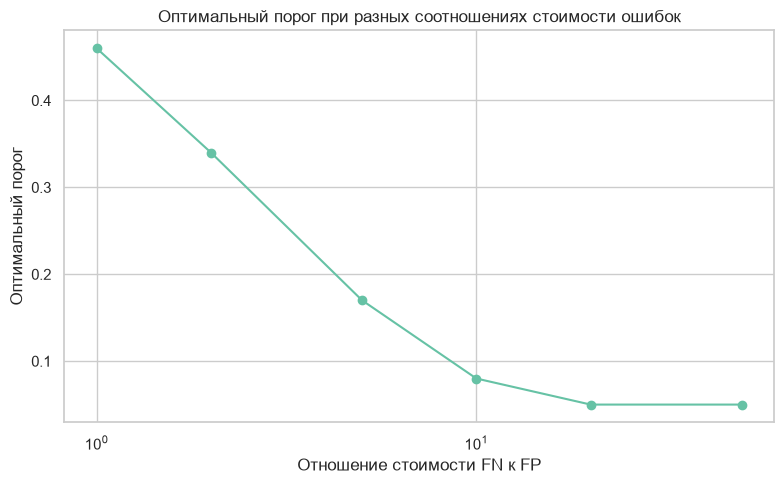

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    cost_sensitivity.index,
    cost_sensitivity["threshold"],
    marker="o",
)

ax.set_xscale("log")
ax.set_xlabel("Отношение стоимости FN к FP")
ax.set_ylabel("Оптимальный порог")
ax.set_title("Оптимальный порог при разных соотношениях стоимости ошибок")

plt.tight_layout()
plt.show()

Оптимальный порог сильно зависит от отношения стоимости FN к FP:

| Отношение FN/FP | Порог | Precision | Recall | F1 | Доля отмеченных |
|---:|---:|---:|---:|---:|---:|
| 1 | 0,46 | 0,6533 | 0,5686 | 0,6080 | 23,09% |
| 2 | 0,34 | 0,5644 | 0,7298 | 0,6365 | 34,31% |
| 5 | 0,17 | 0,4515 | 0,9003 | 0,6014 | 52,91% |
| 10 | 0,08 | 0,3645 | 0,9712 | 0,5300 | 70,71% |
| 20 | 0,05 | 0,3420 | 0,9866 | 0,5079 | 76,55% |
| 50 | 0,05 | 0,3420 | 0,9866 | 0,5079 | 76,55% |

Чем дороже пропущенный уход, тем ниже оптимальный порог и больше клиентов попадает в группу риска. При отношении 20–50 модель отмечает около 77% клиентов: это может быть нереалистично для отдела удержания, даже если математически снижает ожидаемые потери.

Порог 0,2781 попадает в диапазон между отношениями стоимости 2 и 5. Это значит, что он соответствует ситуации, когда потеря уходящего клиента в несколько раз дороже лишнего контакта. Анализ показывает не реальный ROI, а чувствительность решения к бизнес-допущениям.

## 3. Выводы

**Калибровка.** Random Forest уже даёт достаточно хорошие вероятности: Brier score 0,1364, log loss 0,4190, калибровочная кривая близка к диагонали. Sigmoid и isotonic почти не меняют ROC-AUC и PR-AUC; isotonic немного улучшает Brier score и log loss, но выигрыш минимален. Для ранжирования клиентов калибровка не обязательна, для интерпретации вероятностей как реальных шансов ухода — полезна.

**Порог и стоимость.** Оптимальный порог зависит от отношения стоимости FN к FP: при отношении 1 он около 0,46, при 5 — около 0,17, при 10 — около 0,08. Порог 0,2781 соответствует отношению между 2 и 5. При очень высоких отношениях модель отмечает почти всех клиентов, что может быть неприменимо на практике из-за ограниченной мощности отдела удержания.

**Ограничения.** Стоимости ошибок гипотетические: в датасете нет цены контакта, скидки и маржинальности. Анализ показывает чувствительность решения, а не реальный экономический эффект. Калибровка и порог проверены на одном срезе данных; для внедрения нужны временная валидация и бизнес-эксперимент.